In [1]:
## Gotta turn this into a more proper looking script at some point.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os
import random

In [3]:
import re
from pathlib import Path
from datetime import datetime
from typing import Optional, Tuple, List

TOL = 1e-6  # float comparison tolerance
_TS_RE = re.compile(r'(\d{4}-\d{2}-\d{2})_(\d{6})$')

def parse_run_dt(name: str) -> Optional[datetime]:
    """
    Extract run timestamp from directory name.

    Handles names like:
      - '2025-09-19_170029'
      - 'HSIUM-126-2025-09-19_170029'

    Returns a datetime object, or None if parsing fails.
    """
    m = _TS_RE.search(name)
    if not m:
        return None

    date_str, time_str = m.groups()
    try:
        return datetime.strptime(f"{date_str}_{time_str}", "%Y-%m-%d_%H%M%S")
    except ValueError:
        return None

def read_metadata(run_dir: Path) -> Tuple[Optional[float], Optional[float]]:
    """
    Parse README.md assuming fixed lines like:
      - bottomLight : 100.0
      - exposure : 23.5
    Returns (bottom_light, exposure) as floats (or None if missing/unparseable).
    """
    readme = run_dir / "README.md"
    if not readme.exists():
        print(f"{run_dir}: ReadMe doesn't exist")
        return None, None

    bottom_light = None
    exposure = None

    try:
        with readme.open("r", errors="ignore") as f:
            for raw in f:
                line = raw.strip()
                # Normalize the leading dash and spaces
                if line.startswith("- "):
                    key_val = line[2:]  # drop "- "
                else:
                    key_val = line

                if key_val.lower().startswith("bottomlight"):
                    # split on first ":" only
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            bottom_light = float(parts[1].strip())
                        except ValueError:
                            pass

                elif key_val.lower().startswith("exposure"):
                    parts = key_val.split(":", 1)
                    if len(parts) == 2:
                        try:
                            exposure = float(parts[1].strip())
                        except ValueError:
                            pass
    except Exception:
        return None, None

    #print(f"ReadMe checks: {run_dir}\n Bottom Light:{bottom_light}, Exposure: {exposure}")

    return bottom_light, exposure

def choose_best_run(section_dir: Path, cutoff: Optional[datetime] = None) -> Optional[Path]:
    """
    Pick ONE run dir for a section using:
      1) bottomLight == 100.0 preferred
      2) among those, highest exposure
      3) tie-break: newest timestamp
      4) if none with bottom==100, pick highest exposure; else newest
    Respects optional `cutoff` (run timestamp must be >= cutoff).
    """
    candidates: List[dict] = []

    for run_dir in section_dir.iterdir():
        if not run_dir.is_dir():
            continue
        dt = parse_run_dt(run_dir.name)
        if not dt:
            continue
        if cutoff and dt < cutoff:
            continue

        #print(f"Before ReadMe checks: {run_dir}\n")

        bottom, exposure = read_metadata(run_dir)
        #print(f"After ReadMe checks: {run_dir}\n Bottom Light:{bottom}, Exposure: {exposure}")
        candidates.append({
            "path": run_dir,
            "dt": dt,
            "bottom": bottom,
            "exposure": exposure,
            "has_bottom_100": (bottom is not None and abs(bottom - 100.0) < TOL),
            "has_exposure": (exposure is not None),
        })

    #print(f"Candidates:\n {candidates}")

    if not candidates:
        return None

    # Prefer pool: bottomLight==100.0, otherwise all
    pool = [c for c in candidates if c["has_bottom_100"]] or candidates
    #print(f"Pool:\n {pool}")

    # Sort:
    #   - first by whether exposure exists (True before False)
    #   - then by exposure value (descending; None treated as -inf)
    #   - then by datetime (ascending, so take last or invert sign)
    def key(c):
        exp_val = c["exposure"] if c["exposure"] is not None else float("-inf")
        return (c["has_exposure"], exp_val, c["dt"])

    # We want highest exposure and newest, so sort ascending by key and take the last
    pool.sort(key=key)
    return pool[-1]["path"]

In [4]:
BASE = Path("/data/icecores/Output/AN/ALHIC/ALHIC2302")

# --- define date cutoff ---
CUTOFF = datetime(2025, 11, 12, 5, 0, 0) # CUTOFF = None to disable

csv_files = []
full_bubble_csv_files = []
for section_dir in sorted(p for p in BASE.iterdir() if p.is_dir() and p.name.startswith("ALHIC2302-")):
    best = choose_best_run(section_dir, cutoff=CUTOFF)
    if "ALHIC2302-51_2" in str(best):
            best = None
    if "ALHIC2302-40" in str(best):
            best = None
    print(f"{section_dir} \nBest: {best}")
    if not best:
        print("Not Best")
        continue
    csv = next(iter(sorted(best.glob("*bubbles_per_cm.csv"))), None)
    full_bubble_csv = next(iter(sorted(best.glob("*bubbleData.csv"))), None)
    if csv:
        csv_files.append(csv)
    else:
        print("No CSV")
    if full_bubble_csv:
        full_bubble_csv_files.append(full_bubble_csv)
    else:
        print("No full bubble CSV")

/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-12/HSIUM-155-2026-03-10_174732
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-13 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-13/HSIUM-152-2026-03-10_174732
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-14 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-14/HSIUM-149-2026-03-10_174732
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-15 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-15/HSIUM-146-2026-03-10_174732
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-155_2 
Best: None
Not Best
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-156_2 
Best: None
Not Best
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-158 
Best: None
Not Best
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-159_3 
Best: /data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC2302-159_3/HSIUM-7-2026-03-10_174732
/data/icecores/Output/AN/ALHIC/ALHIC2302/ALHIC230

In [5]:
#print(csv_files)

In [6]:
all_data = []
for file in csv_files:
    df = pd.read_csv(file)
    all_data.append(df)
    
timestamp = datetime.now().strftime("%Y-%m-%d_%H%M%S")

# === Combine and sort all data === 
combined_df = pd.concat(all_data, ignore_index=True)
combined_df = combined_df.sort_values(by=["Depth_cm"]).reset_index(drop=True)
combined_df = combined_df[combined_df["Depth_cm"] >= 1000]

combined_df["Bubble_Count"] = combined_df["Bubble_Count"] / 25

output_dir = Path(f"/data/icecores/Output//AN/ALHIC/ALHIC2302/FullCoreData/{timestamp}")
output_dir.mkdir(parents=True, exist_ok=False) 
combined_df.to_csv(f"{output_dir}/combinedBubbles.csv", index=False)
print("Output Dir: ", output_dir)

full_bubble_data = []
for file in full_bubble_csv_files:
    df = pd.read_csv(file)
    full_bubble_data.append(df)

# === Combine and sort all data === 
full_bubble_df = pd.concat(full_bubble_data, ignore_index=True)
full_bubble_df = full_bubble_df.sort_values(by=["depth_cm"]).reset_index(drop=True)
full_bubble_df = full_bubble_df[full_bubble_df["depth_cm"] >= 1000]
output_dir = Path(f"/data/icecores/Output//AN/ALHIC/ALHIC2302/FullCoreData/{timestamp}")
full_bubble_df.to_csv(f"{output_dir}/full_bubble.csv", index=False)
print("Output Dir: ", output_dir)

Output Dir:  /data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-13_212847
Output Dir:  /data/icecores/Output/AN/ALHIC/ALHIC2302/FullCoreData/2026-03-13_212847


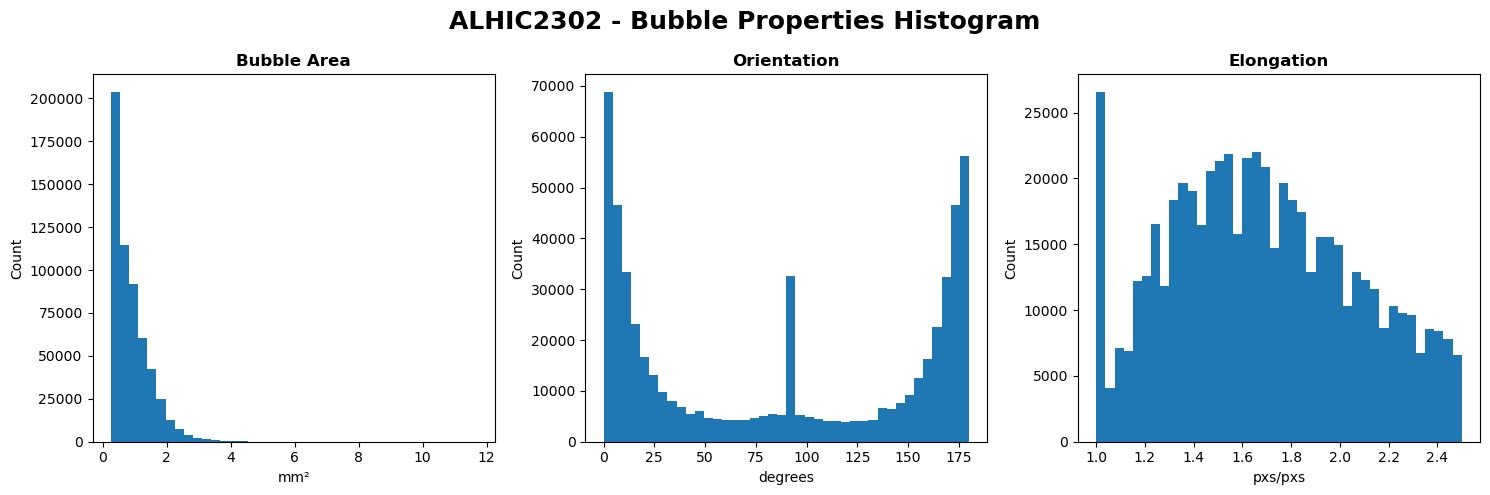

In [7]:
import matplotlib.pyplot as plt

# Columns to summarize
cols = [
    ("area", "Bubble Area", "mm²"),
    ("orientation", "Orientation", "degrees"),
    ("elongation", "Elongation", "pxs/pxs")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (col, label, x) in zip(axes, cols):
    data = full_bubble_df[col].dropna().values
    
    ax.hist(data, bins=40)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel(x)
    ax.set_ylabel("Count")


fig.suptitle("ALHIC2302 - Bubble Properties Histogram", fontsize=18, fontweight='bold')
plt.tight_layout()
out_path = output_dir / f"bubble_histograms.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


Fixing outliers in 'Bubble_Count' using rolling median (window=5, threshold=3.0):


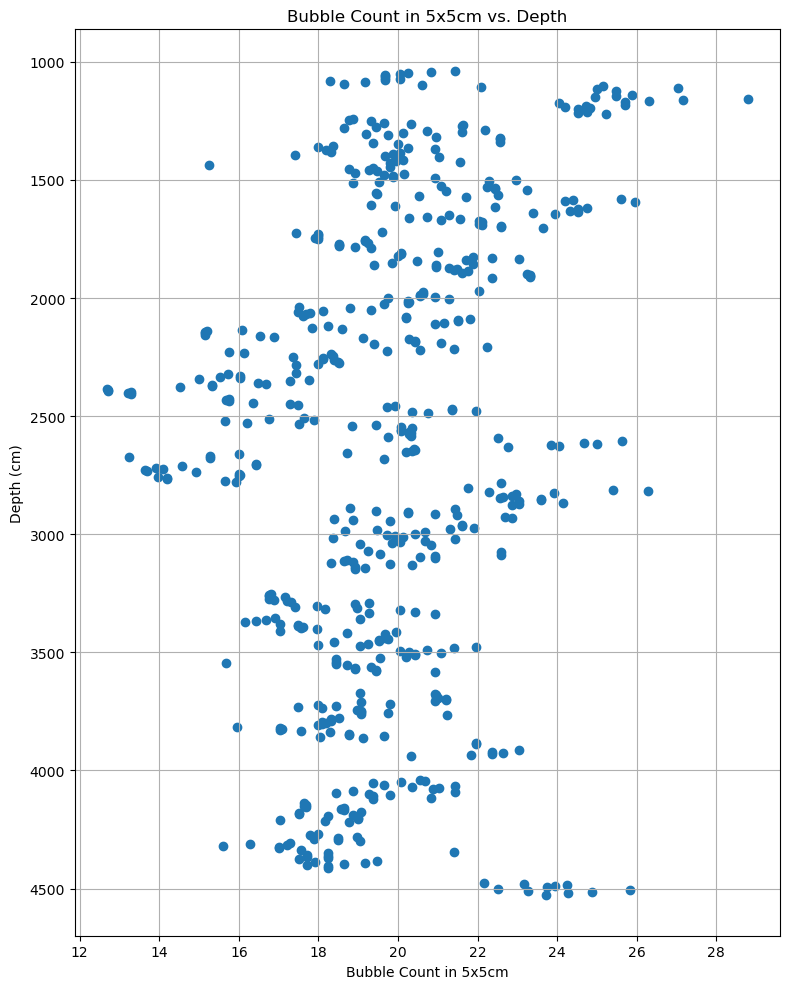


Fixing outliers in 'Avg_Bubble_Size' using rolling median (window=5, threshold=3.0):


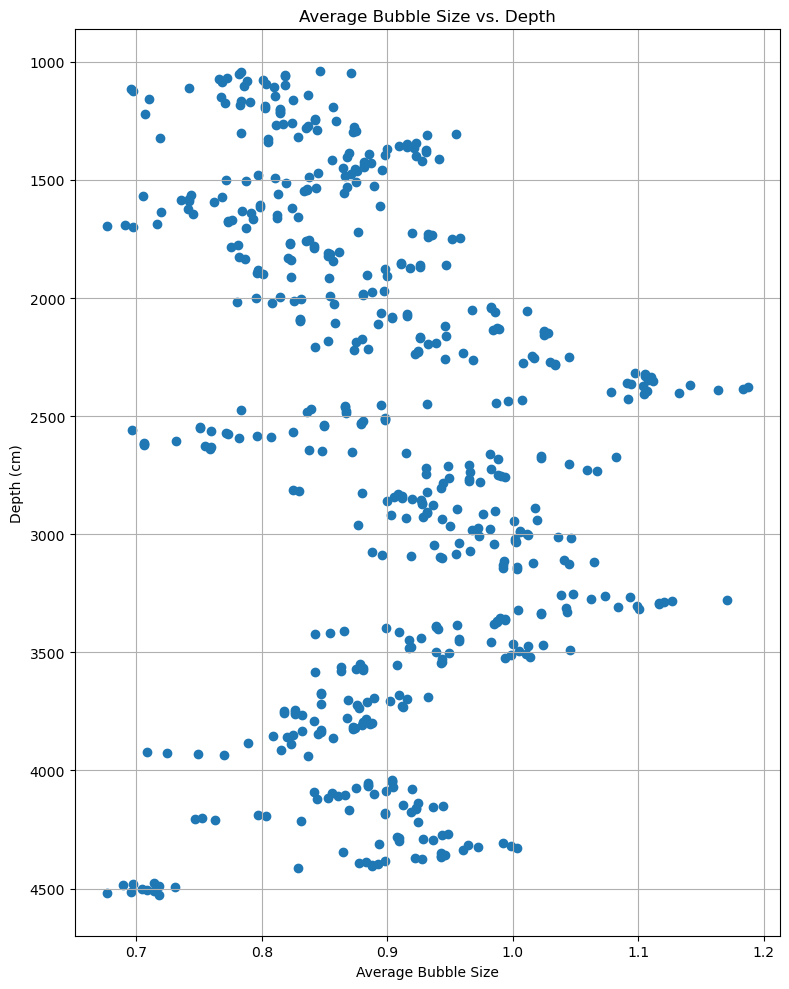


Fixing outliers in 'Avg_Orientation' using rolling median (window=5, threshold=3.0):


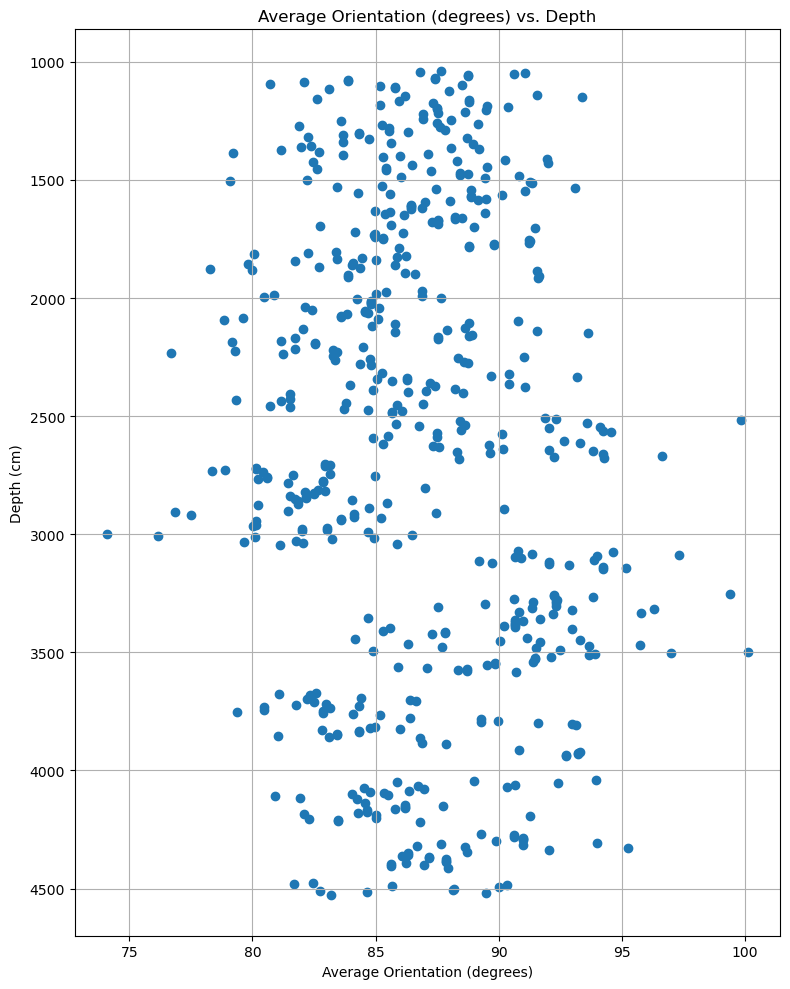


Fixing outliers in 'Avg_Elongation' using rolling median (window=5, threshold=3.0):


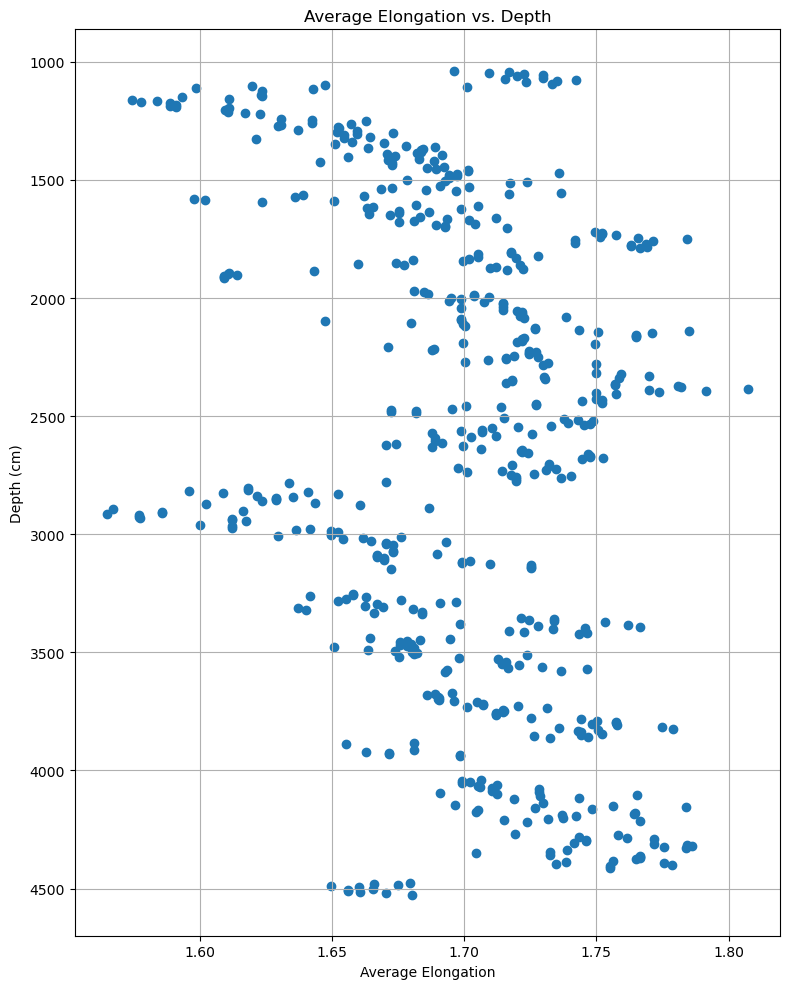

In [8]:
def smooth_outliers_rolling(df: pd.DataFrame, column: str, window: int = 5, threshold: float = 3.0) -> pd.Series:
    series = df[column]
    rolling_median = series.rolling(window=window, center=True).median()
    
    # Calculate deviation from rolling median
    deviation = (series - rolling_median).abs()
    mad = deviation.rolling(window=window, center=True).median()  # Median Absolute Deviation
    
    # Flag outliers: values farther than threshold * MAD from the rolling median
    outliers = deviation > (threshold * mad)
    
    if outliers.any():
        print(f"\nFixing outliers in '{column}' using rolling median (window={window}, threshold={threshold}):")
        #print(df.loc[outliers, ["Depth_cm", column]].to_string(index=False))
    
    # Replace outliers with rolling median values
    fixed_series = series.copy()
    fixed_series[outliers] = rolling_median[outliers]
    
    return fixed_series

file = f"{output_dir}/combinedBubbles.csv"
combined_df = pd.read_csv(file)

# === Define variables to plot ===
plot_vars = [
    ("Bubble_Count", "Bubble Count in 5x5cm", None),
    ("Avg_Bubble_Size", "Average Bubble Size", "STD_Bubble_Size"),
    ("Avg_Orientation", "Average Orientation (degrees)", "STD_Orientation"),
    ("Avg_Elongation", "Average Elongation", "STD_Elongation")
]

# === Plot each variable vs depth (depth on y-axis) ===
for var, label, std in plot_vars:
    combined_df[var] = smooth_outliers_rolling(combined_df, var, window=5, threshold=3.0)

    plt.figure(figsize=(8, 10))
    plt.scatter(combined_df[var], combined_df["Depth_cm"])

    plt.xlabel(label)
    plt.ylabel("Depth (cm)")
    plt.title(f"{label} vs. Depth")
    plt.gca().invert_yaxis()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{var}bubbleGraph.png", dpi=300, bbox_inches='tight')
    plt.show()

ValueError: 'xerr' must not contain negative values

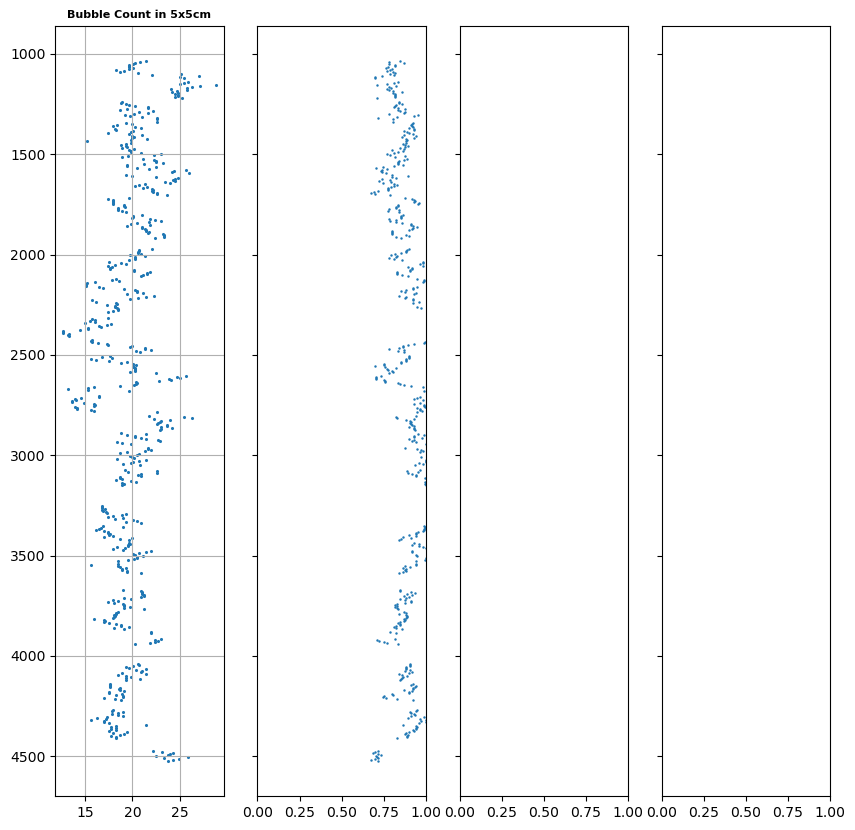

In [9]:
# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label, stdev) in zip(axes, plot_vars):
    if stdev != None:
        x = combined_df[var].to_numpy()
        x_low = (combined_df[var] - combined_df[stdev]).to_numpy()
        x_high = (combined_df[stdev] - combined_df[var]).to_numpy()
        # Gray 5–95% error bars
        ax.errorbar(
            x,
            combined_df["Depth_cm"],
            xerr=[x_low, x_high],
            fmt='.',
            markersize=1.5,
            ecolor="lightgray",
            elinewidth=0.8,
            capsize=0,
            color="tab:blue",
            label="+/- 1 σ"
        )
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
def smooth_outliers_rolling(df: pd.DataFrame, column: str, window: int = 5, threshold: float = 3.0) -> pd.Series:
    series = df[column]
    rolling_median = series.rolling(window=window, center=True).median()
    
    # Calculate deviation from rolling median
    deviation = (series - rolling_median).abs()
    mad = deviation.rolling(window=window, center=True).median()  # Median Absolute Deviation
    
    # Flag outliers: values farther than threshold * MAD from the rolling median
    outliers = deviation > (threshold * mad)
    
    if outliers.any():
        print(f"\nFixing outliers in '{column}' using rolling median (window={window}, threshold={threshold}):")
        #print(df.loc[outliers, ["Depth_cm", column]].to_string(index=False))
    
    # Replace outliers with rolling median values
    fixed_series = series.copy()
    fixed_series[outliers] = rolling_median[outliers]
    
    return fixed_series

file = f"{output_dir}/combinedBubbles.csv"
combined_df = pd.read_csv(file)

# === Define variables to plot ===
plot_vars = [
    ("Bubble_Count", "Bubble Count in 5x5cm"),
    ("Median_Bubble_Size", "Median Bubble Size"),
    ("Median_Orientation", "Median Orientation (degrees)"),
    ("Median_Elongation", "Median Elongation")
]

# === Plot each variable vs depth (depth on y-axis) ===
for var, label in plot_vars:
    combined_df[var] = smooth_outliers_rolling(combined_df, var, window=5, threshold=3.0)

    plt.figure(figsize=(8, 10))
    plt.scatter(combined_df[var], combined_df["Depth_cm"])

    plt.xlabel(label)
    plt.ylabel("Depth (cm)")
    plt.title(f"{label} vs. Depth")
    plt.gca().invert_yaxis()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{var}bubbleGraph.png", dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plt.figure(figsize=(10, 10))

plt.scatter(combined_df["Bubble_Count"], combined_df["Median_Bubble_Size"])
z = np.polyfit(combined_df["Bubble_Count"], combined_df["Median_Bubble_Size"], 1)
p = np.poly1d(z)
plt.plot(combined_df["Bubble_Count"],p(combined_df["Bubble_Count"]),"r--")

plt.xlabel("Count")
plt.ylabel("Size")
plt.title("ALHIC2302\nBubble Number and Size Correlation")
plt.grid(True)
plt.tight_layout()
outputPath = '/data/icecores/Output/Figures'
out_path = f"{outputPath}/ALHIC2302_BubbleSizeCorrelation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
plt.figure(figsize=(10, 10))

plt.scatter(combined_df["Bubble_Count"], combined_df["Avg_Bubble_Size"])
z = np.polyfit(combined_df["Bubble_Count"], combined_df["Median_Bubble_Size"], 1)
p = np.poly1d(z)
plt.plot(combined_df["Bubble_Count"],p(combined_df["Bubble_Count"]),"r--")

plt.xlabel("Count")
plt.ylabel("Size")
plt.title("ALHIC2302\nBubble Number and Size Correlation")
plt.grid(True)
plt.tight_layout()
outputPath = '/data/icecores/Output/Figures'
out_path = f"{outputPath}/ALHIC2302_BubbleSizeCorrelation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
combined_df["Depth_Diff"] = combined_df["Depth_cm"].diff()

gap_threshold = 10
gap_mask = combined_df["Depth_Diff"] > gap_threshold
gap_indices = combined_df.index[gap_mask].tolist()

# --- Get depth ranges for each gap ---
gap_ranges = []
for idx in gap_indices:
    start = combined_df.loc[idx - 1, "Depth_cm"]
    end = combined_df.loc[idx, "Depth_cm"]
    gap_ranges.append((start, end))

# Drop helper column
combined_df = combined_df.drop(columns="Depth_Diff")

# --- Plot the data with gap shading ---
fig, axes = plt.subplots(nrows=1, ncols=len(plot_vars), figsize=(2.5 * len(plot_vars), 10), sharey=True)

for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=10)
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

    # Shade gaps
    for start, end in gap_ranges:
        ax.axhspan(start, end, color='gray', alpha=0.15)

# Add shared y-label
axes[0].set_ylabel("Depth (cm)")
axes[0].invert_yaxis()

plt.tight_layout()
plt.suptitle("Bubble Properties vs Depth (Gaps Shaded)", y=1.02, fontsize=14)
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleGraph_GapsShaded.png", dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
plot_vars = [
    ("Avg_Bubble_Size", "Average Bubble Size"),
    ("STD_Bubble_Size", "Bubble Size STD"),
    ("Trimmed_Mean_Bubble_Size", "Trimmed Average Size")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleSizeGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plot_vars = [
    ("Avg_Elongation", "Average Bubble Elongation"),
    ("STD_Elongation", "Bubble Elongation STD"),
    ("Trimmed_Mean_Elongation", "Trimmed Average Elongation")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleElongationGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plot_vars = [
    ("Avg_Eccentricity", "Average Bubble Eccentricity"),
    ("STD_Eccentricity", "Eccentricity STD"),
    ("Trimmed_Mean_Eccentricity", "Trimmed Average Eccentricity")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleEccentricityGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
plot_vars = [
    ("Avg_Orientation", "Average Bubble Orientation"),
    ("STD_Orientation", "Orientation STD"),
    ("Trimmed_Mean_Orientation", "Trimmed Average Orientation")
]

# === Create figure with horizontally stacked subplots ===
n_vars = len(plot_vars)
fig, axes = plt.subplots(nrows=1, ncols=n_vars, figsize=(2.5 * n_vars, 10), sharey=True)
#fig.subplots_adjust(wspace=0, hspace=0)

# === Plot each variable in its own vertical panel ===
for ax, (var, label) in zip(axes, plot_vars):
    ax.scatter(combined_df[var], combined_df["Depth_cm"], s=1.5)
    ax.set_title(label, fontsize=8, fontweight='bold')
    ax.invert_yaxis()
    ax.grid(True)
    #ax.set_xlabel("Value")

# === Set common y-axis label ===
axes[0].set_ylabel("Depth (cm)", fontweight='bold')
#axes[0].invert_yaxis()

# === Final layout tweaks ===
plt.tight_layout()
# plt.suptitle("Horizontally Stacked Bubble Properties vs Depth", y=1.02, fontsize=14, fontweight='bold')
#plt.gca().invert_yaxis()
plt.subplots_adjust(top=0.9)
plt.savefig(f"{output_dir}/StackedBubbleOrientaionGraph.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np

#data = full_bubble_df["area"]
#print(filtered["area"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
counts, bin_edges, patches = plt.hist(full_bubble_df["area"], bins=10, color='skyblue', edgecolor='black')
print("Counts for each bin:")
print(counts)
plt.xlabel("Bubble Size (px²)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Areas")
plt.tight_layout()
#plt.savefig(f"{output_dir}/TotalBubbleSizeHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np

Q1 = full_bubble_df["area"].quantile(0.25)
Q3 = full_bubble_df["area"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["area"] >= lower_bound) & (full_bubble_df["area"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["area"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
counts, bin_edges, patches = plt.hist(filtered["area"], bins=10, color='skyblue', edgecolor='black')
print("Counts for each bin:")
print(counts)
plt.xlabel("Bubble Size (px²)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Areas")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleSizeHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
Q1 = full_bubble_df["orientation"].quantile(0.25)
Q3 = full_bubble_df["orientation"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["orientation"] >= lower_bound) & (full_bubble_df["orientation"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["orientation"])
#bins = np.logspace(np.log10(filtered["orientation"].min()), np.log10(filtered["orientation"].max()), 10)
plt.figure(figsize=(8, 5))
plt.hist(filtered["orientation"], bins=8, color='skyblue', edgecolor='black')
plt.xlabel("Bubble Orientation (degrees)")
plt.ylabel("Count")
plt.title("Distribution of Bubble Orientation")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleOrientationHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
Q1 = full_bubble_df["elongation"].quantile(0.25)
Q3 = full_bubble_df["elongation"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["elongation"] >= lower_bound) & (full_bubble_df["elongation"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")


#data = filtered
print(filtered["elongation"])
#bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 10)
plt.figure(figsize=(8, 5))
plt.hist(filtered["elongation"], bins=10, color='skyblue', edgecolor='black')
plt.xlabel("Bubble Elongation")
plt.ylabel("Count")
plt.title("Distribution of Bubble Elongation")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleElongationHistogram.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import numpy as np

Q1 = full_bubble_df["area"].quantile(0.25)
Q3 = full_bubble_df["area"].quantile(0.75)
IQR = Q3 - Q1

# Define threshold (1.5×IQR is standard, 3×IQR is stricter)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered = full_bubble_df[(full_bubble_df["area"] >= lower_bound) & (full_bubble_df["area"] <= upper_bound)]

print(f"Removed {len(full_bubble_df) - len(filtered)} outliers")

# Make 2D histogram
plt.figure(figsize=(8, 6))
h = plt.hist2d(
    filtered["area"],        # x-axis
    filtered["depth_cm"],    # y-axis
    bins=(10, 10),          # adjust resolution
    cmap="viridis"
)

plt.gca().invert_yaxis()
plt.colorbar(h[3], label="Count")
plt.ylabel("Depth (cm)")
plt.xlabel("Bubble Size (px²)")
plt.title("2D Histogram: Bubble Size vs Depth")
plt.tight_layout()
plt.savefig(f"{output_dir}/TotalBubbleSize2dHistogram.png", dpi=300, bbox_inches='tight')
plt.show()